# Portfolio Assessment 3: Advanced ML - LSTM for Regression - Option 3b
Le Mai Chi | 105555880

This notebook is Appendix A of the report. It holds the code and stored outputs; the report holds the discussion.

In [1]:
from pathlib import Path
import os, sys, time, pickle
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"  # hide TensorFlow C++ log noise
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import joblib
import tensorflow as tf
from tensorflow import keras

from sklearn.model_selection import GroupShuffleSplit, GroupKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.ensemble import RandomForestRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import r2_score, root_mean_squared_error, mean_absolute_error

print("Python      :", sys.version.split()[0])
print("scikit-learn:", sklearn.__version__)
print("tensorflow  :", tf.__version__)

SEED = 42
keras.utils.set_random_seed(SEED)  # python, numpy and tensorflow
tf.config.experimental.enable_op_determinism()

pd.set_option("display.max_columns", 100)
pd.set_option("display.float_format", lambda x: f"{x:.4f}")

DATA = Path("../output/nasa_battery_eda_clean.csv")
OUT = Path("output/")
FIG_DIR, TAB_DIR, MODEL_DIR = OUT / "figures", OUT / "tables", OUT / "models"
for d in (FIG_DIR, TAB_DIR, MODEL_DIR):
    d.mkdir(parents=True, exist_ok=True)

def save_fig(name):
    plt.savefig(FIG_DIR / f"{name}.png", dpi=200, bbox_inches="tight")

def save_table(df, name):
    df.to_csv(TAB_DIR / f"{name}.csv", index=False)
    return df

Python      : 3.12.13
scikit-learn: 1.9.1
tensorflow  : 2.21.0


## Part A: Traditional Machine Learning
### A.1 Load and analyse the dataset

In [2]:
df = pd.read_csv(DATA)
print("Shape:", df.shape, "| batteries:", df["battery_id"].nunique())
print("Columns:", list(df.columns))

assert pd.api.types.is_float_dtype(df["Capacity"])
print(f"Target Capacity: continuous, {df['Capacity'].nunique()} unique values in "
      f"[{df['Capacity'].min():.3f}, {df['Capacity'].max():.3f}] Ah -> regression")
display(df["Capacity"].describe().to_frame("Capacity (Ah)").T)

PREDICTORS = [
    "discharge_index", "ambient_temperature",
    "mean_voltage", "min_voltage", "max_voltage", "voltage_std", "voltage_drop",
    "mean_abs_current", "max_abs_current", "current_std",
    "mean_temperature", "max_temperature", "temperature_rise",
    "mean_abs_load_current", "mean_load_voltage",
]
EXCLUDED = ["capacity_class", "n_samples", "discharge_duration_s", "test_id", "uid", "filename"]
assert not set(PREDICTORS) & set(EXCLUDED + ["Capacity", "battery_id"]), "leaky column"
print("Predictors:", len(PREDICTORS), "| excluded:", EXCLUDED)

Shape: (2750, 23) | batteries: 34
Columns: ['n_samples', 'discharge_duration_s', 'mean_voltage', 'min_voltage', 'max_voltage', 'voltage_std', 'voltage_drop', 'mean_abs_current', 'max_abs_current', 'current_std', 'mean_temperature', 'max_temperature', 'temperature_rise', 'mean_abs_load_current', 'mean_load_voltage', 'battery_id', 'test_id', 'uid', 'filename', 'ambient_temperature', 'Capacity', 'discharge_index', 'capacity_class']
Target Capacity: continuous, 2750 unique values in [0.033, 2.640] Ah -> regression


,count,mean,std,min,25%,50%,75%,max
Capacity (Ah),2750.0000,1.3357,0.4611,0.0326,1.1564,1.4306,1.6744,2.6401


Predictors: 15 | excluded: ['capacity_class', 'n_samples', 'discharge_duration_s', 'test_id', 'uid', 'filename']


### A.2 Preprocess

In [3]:
X, y, groups = df[PREDICTORS], df["Capacity"], df["battery_id"]

gss = GroupShuffleSplit(n_splits=1, test_size=0.30, random_state=SEED)
train_idx, test_idx = next(gss.split(X, y, groups))
X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
g_train = groups.iloc[train_idx]
train_bats, test_bats = sorted(g_train.unique()), sorted(groups.iloc[test_idx].unique())
assert set(train_bats).isdisjoint(test_bats), "battery leakage"

# The scaler is refitted inside every fit, so it only sees training rows
def make_pipe(model):
    return Pipeline([("scale", StandardScaler()), ("model", model)])

shapes = save_table(pd.DataFrame({
    "split": ["train", "test"],
    "batteries": [len(train_bats), len(test_bats)],
    "samples": [len(X_train), len(X_test)],
    "features": [X_train.shape[1], X_test.shape[1]],
}), "table_1_split_shapes")
display(shapes)
print("Test batteries:", test_bats)

,split,batteries,samples,features
0,train,23,1821,15
1,test,11,929,15


Test batteries: ['B0005', 'B0029', 'B0030', 'B0033', 'B0038', 'B0042', 'B0044', 'B0047', 'B0049', 'B0050', 'B0055']


### A.3 Train 2 traditional models

In [4]:
models = {
    "Random Forest": make_pipe(RandomForestRegressor(n_estimators=300, random_state=SEED, n_jobs=-1)),
    "MLP": make_pipe(MLPRegressor(hidden_layer_sizes=(64, 32), early_stopping=True, max_iter=2000, random_state=SEED)),
}
preds = {name: m.fit(X_train, y_train).predict(X_test) for name, m in models.items()}

### A.4 Evaluate and compare

In [5]:
def metrics(y_true, y_pred):
    return {"R2": r2_score(y_true, y_pred),
            "RMSE": root_mean_squared_error(y_true, y_pred),
            "MAE": mean_absolute_error(y_true, y_pred)}

CV = GroupKFold(n_splits=5, shuffle=True, random_state=SEED)

rows = []
for name, m in models.items():
    cv = cross_val_score(m, X_train, y_train, groups=g_train, cv=CV, scoring="r2")
    rows.append({"model": name, "cv_R2_mean": cv.mean(), "cv_R2_sd": cv.std(),
                 **{f"test_{k}": v for k, v in metrics(y_test, preds[name]).items()}})
trad_table = save_table(pd.DataFrame(rows).round(4), "table_2_traditional_comparison")
display(trad_table)

BEST_A = trad_table.loc[trad_table["cv_R2_mean"].idxmax(), "model"]
print("Best traditional model by grouped-CV R2:", BEST_A)

,model,cv_R2_mean,cv_R2_sd,test_R2,test_RMSE,test_MAE
0,Random Forest,0.7566,0.2020,0.5249,0.3418,0.1377
1,MLP,0.6311,0.2426,0.6552,0.2912,0.1531


Best traditional model by grouped-CV R2: Random Forest


### A.5 Visualise

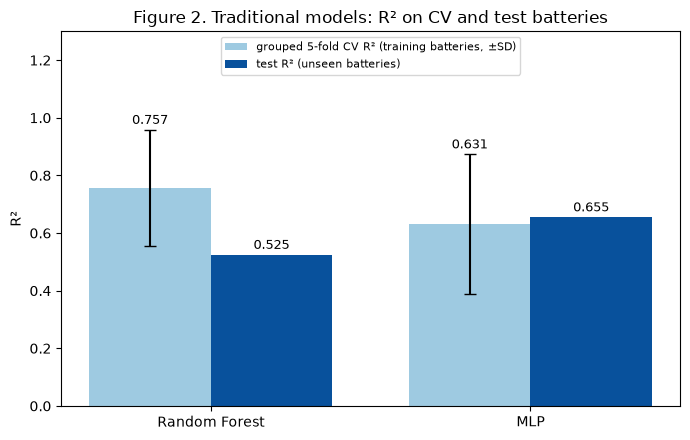

In [6]:
fig, ax = plt.subplots(figsize=(7, 4.5))
x = np.arange(len(trad_table)); w = 0.38
ax.bar(x - w / 2, trad_table["cv_R2_mean"], w, yerr=trad_table["cv_R2_sd"], capsize=4,
       color="#9ecae1", label="grouped 5-fold CV R² (training batteries, ±SD)")
ax.bar(x + w / 2, trad_table["test_R2"], w, color="#08519c", label="test R² (unseen batteries)")
for i, r in trad_table.iterrows():
    ax.text(i - w / 2, max(r["cv_R2_mean"] + r["cv_R2_sd"], 0) + 0.02, f'{r["cv_R2_mean"]:.3f}', ha="center", fontsize=9)
    ax.text(i + w / 2, max(r["test_R2"], 0) + 0.02, f'{r["test_R2"]:.3f}', ha="center", fontsize=9)
ax.set_xticks(x, trad_table["model"])
ax.set_ylim(min(0, (trad_table["cv_R2_mean"] - trad_table["cv_R2_sd"]).min() - 0.05), 1.3)
ax.set_ylabel("R²")
ax.legend(loc="upper center", fontsize=8)
ax.set_title("Figure 2. Traditional models: R² on CV and test batteries")
plt.tight_layout()
save_fig("figure_02_traditional_r2")
plt.show()

## Part B: LSTM for Regression

### B.1 Prepare sequential data

In [13]:
seq = df.sort_values(["battery_id", "discharge_index"]).reset_index(drop=True)
step = seq.groupby("battery_id")["discharge_index"].diff()
breaks = seq.loc[step > 1, ["battery_id", "discharge_index"]].assign(missing=(step[step > 1] - 1).astype(int))
print(f"Index breaks: {len(breaks)} across {breaks['battery_id'].nunique()} batteries "
      f"(missing discharges per break: median {breaks['missing'].median():.0f}, max {breaks['missing'].max()})")
display(breaks.T)
# Breaks are kept: windows follow the observed order and discharge_index stays an input, so each jump is visible

# Past Capacity is not an input: with it the LSTM reduces to a persistence forecast, and Part A has no Capacity input
USE_PAST_CAPACITY = False
SEQ_FEATURES = PREDICTORS + (["Capacity"] if USE_PAST_CAPACITY else [])
N_FEATURES = len(SEQ_FEATURES)

def make_windows(frame, L):
    """Windows of L consecutive discharges inside each battery; label = Capacity of the next discharge."""
    X, y, idx = [], [], []
    for _, b in frame.groupby("battery_id", sort=False):
        feats, target = b[SEQ_FEATURES].to_numpy(np.float32), b["target"].to_numpy(np.float32)
        for t in range(L, len(b)):
            X.append(feats[t - L:t]); y.append(target[t]); idx.append(b.index[t])
    return np.array(X).reshape(-1, L, N_FEATURES), np.array(y), np.array(idx)

cycles = seq.groupby("battery_id").size().sort_values()
split_of = lambda b: "test" if b in test_bats else "train"
L_GRID = [5, 10, 20, 50]
win_table = save_table(pd.DataFrame([{
    "L": L,
    "usable_batteries": int((cycles > L).sum()),
    "windows": int((cycles - L).clip(lower=0).sum()),
    "train_windows": int(sum(max(n - L, 0) for b, n in cycles.items() if split_of(b) == "train")),
    "test_windows": int(sum(max(n - L, 0) for b, n in cycles.items() if split_of(b) == "test")),
} for L in L_GRID]), "table_B1_windows_per_L")
display(win_table)

Index breaks: 17 across 10 batteries (missing discharges per break: median 1, max 1)


,1712,1823,1934,2059,2104,2129,2162,2173,2198,2231,2242,2267,2300,2311,2333,2357,2377
battery_id,B0042,B0043,B0044,B0045,B0045,B0046,B0046,B0046,B0047,B0047,B0047,B0048,B0048,B0048,B0049,B0050,B0051
discharge_index,7,7,7,21,67,21,55,67,21,55,67,21,55,67,18,18,18
missing,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1


,L,usable_batteries,windows,train_windows,test_windows
0,5,33,2581,1707,874
1,10,33,2416,1597,819
2,20,32,2086,1377,709
3,50,19,1315,857,458


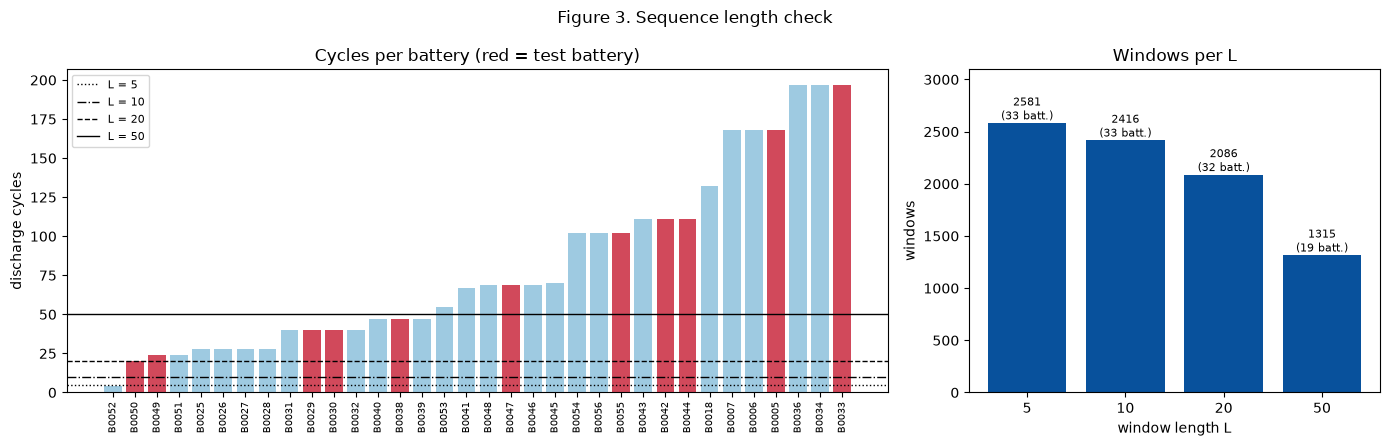

Validation batteries: ['B0006', 'B0032', 'B0034', 'B0045', 'B0048']


In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), gridspec_kw={"width_ratios": [2, 1]})
axes[0].bar(cycles.index, cycles.values, color=["#d1495b" if b in test_bats else "#9ecae1" for b in cycles.index])
for L, ls in zip(L_GRID, [":", "-.", "--", "-"]):
    axes[0].axhline(L, ls=ls, lw=1, color="black", label=f"L = {L}")
axes[0].legend(loc="upper left", fontsize=8)
axes[0].tick_params(axis="x", rotation=90, labelsize=7)
axes[0].set_ylabel("discharge cycles")
axes[0].set_title("Cycles per battery (red = test battery)")
axes[1].bar(win_table["L"].astype(str), win_table["windows"], color="#08519c")
for i, r in win_table.iterrows():
    axes[1].text(i, r["windows"], f'{r["windows"]}\n({r["usable_batteries"]} batt.)', ha="center", va="bottom", fontsize=8)
axes[1].set_ylim(0, win_table["windows"].max() * 1.2)
axes[1].set_xlabel("window length L"); axes[1].set_ylabel("windows")
axes[1].set_title("Windows per L")
fig.suptitle("Figure 3. Sequence length check")
plt.tight_layout()
save_fig("figure_03_windows_per_L")
plt.show()

tb = np.array(train_bats)
fit_i, val_i = next(GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=SEED).split(tb, groups=tb))
fit_bats, val_bats = tb[fit_i], tb[val_i]
print("Validation batteries:", [str(b) for b in val_bats])

fit_rows = seq["battery_id"].isin(fit_bats)
x_scaler = MinMaxScaler().fit(seq.loc[fit_rows, SEQ_FEATURES])
y_scaler = MinMaxScaler().fit(seq.loc[fit_rows, ["Capacity"]])
scaled = seq.copy()
scaled[SEQ_FEATURES] = x_scaler.transform(seq[SEQ_FEATURES])
scaled["target"] = y_scaler.transform(seq[["Capacity"]]).ravel()


In [15]:
def make_split(L):
    return {name: make_windows(scaled[scaled["battery_id"].isin(bats)], L)
            for name, bats in [("train", fit_bats), ("val", val_bats), ("test", test_bats)]}

L1, L2 = 10, 5
dl1, dl2 = make_split(L1), make_split(L2)
display(pd.DataFrame([{"L": L, "split": s, "batteries": len(b), "X_shape (samples, timesteps, features)": data[s][0].shape,
                       "y_shape": data[s][1].shape}
                      for L, data in [(L1, dl1), (L2, dl2)]
                      for s, b in [("train", fit_bats), ("val", val_bats), ("test", test_bats)]]))

,L,split,batteries,"X_shape (samples, timesteps, features)",y_shape
0,10,train,18,"(1103, 10, 15)","(1103,)"
1,10,val,5,"(494, 10, 15)","(494,)"
2,10,test,11,"(819, 10, 15)","(819,)"
3,5,train,18,"(1188, 5, 15)","(1188,)"
4,5,val,5,"(519, 5, 15)","(519,)"
5,5,test,11,"(874, 5, 15)","(874,)"


### B.2 Build the LSTM architecture

In [21]:
def build_lstm(L, n_features):
    model = keras.Sequential([
        keras.Input(shape=(L, n_features)),
        keras.layers.LSTM(64, return_sequences=True),
        keras.layers.Dropout(0.2),
        keras.layers.LSTM(32),
        keras.layers.Dropout(0.2),
        keras.layers.Dense(16, activation="relu"),
        keras.layers.Dense(1, activation="linear"),
    ], name=f"lstm_L{L}")
    model.compile(optimizer=keras.optimizers.Adam(), loss="mse", metrics=["mae"])
    return model

build_lstm(L1, N_FEATURES).summary()

Model: "lstm_L10"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_10 (LSTM)                  │ (None, 10, 64)         │        20,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_10 (Dropout)            │ (None, 10, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_11 (LSTM)                  │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_11 (Dropout)            │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 33,441 (130.63 KB)

 Trainable params: 33,441 (130.63 KB)

 Non-trainable params: 0 (0.00 B)

### B.3 Train the model

In [23]:
BATCH_SIZES = [16, 32, 64]
EPOCHS = 50

def train_lstm(data, L, batch_size):
    keras.utils.set_random_seed(SEED)
    model = build_lstm(L, N_FEATURES)
    callbacks = [keras.callbacks.EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True),
                 keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=5)]
    start = time.time()
    hist = model.fit(*data["train"][:2], validation_data=data["val"][:2], epochs=EPOCHS,
                     batch_size=batch_size, callbacks=callbacks, verbose=0)
    return model, hist.history, time.time() - start

def run_summary(h, **extra):
    best = int(np.argmin(h["val_loss"]))
    return {**extra, "epochs_run": len(h["loss"]), "best_epoch": best + 1,
            "train_loss_at_best": h["loss"][best], "best_val_loss_mse": h["val_loss"][best],
            "val_mae_at_best": h["val_mae"][best]}

runs = {bs: train_lstm(dl1, L1, bs) for bs in BATCH_SIZES}
bs_table = save_table(pd.DataFrame([run_summary(h, L=L1, batch_size=bs, train_time_s=t)
for bs, (_, h, t) in runs.items()]).round(5), "table_3_batch_size")
display(bs_table)

,L,batch_size,train_time_s,epochs_run,best_epoch,train_loss_at_best,best_val_loss_mse,val_mae_at_best
0,10,16,12.7439,26,16,0.0039,0.0014,0.0282
1,10,32,7.1630,17,7,0.0073,0.0011,0.0258
2,10,64,6.9152,24,14,0.0059,0.0009,0.0234


Chosen batch size (lowest validation loss): 64
Deep Learning 2 (L = 5):


,L,batch_size,train_time_s,epochs_run,best_epoch,train_loss_at_best,best_val_loss_mse,val_mae_at_best
0,5,64,6.1827,18,8,0.0088,0.0021,0.0391


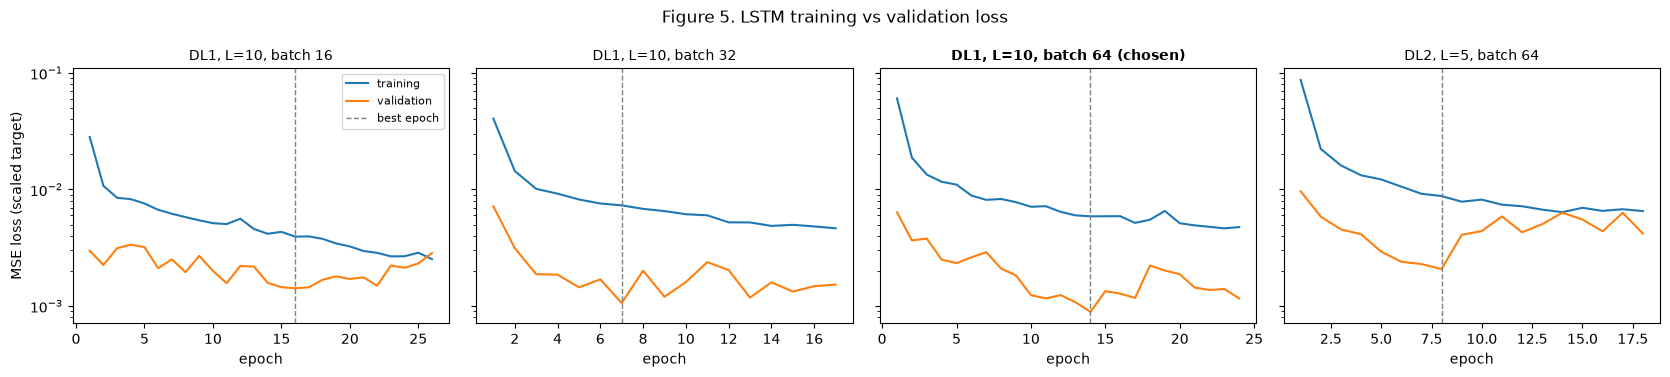

In [24]:
BEST_BS = int(bs_table.loc[bs_table["best_val_loss_mse"].idxmin(), "batch_size"])
lstm1, hist1, _ = runs[BEST_BS]
print("Chosen batch size (lowest validation loss):", BEST_BS)

lstm2, hist2, time2 = train_lstm(dl2, L2, BEST_BS)
dl2_summary = pd.DataFrame([run_summary(hist2, L=L2, batch_size=BEST_BS, train_time_s=time2)]).round(5)
print("Deep Learning 2 (L = 5):")
display(dl2_summary)

curves = [(f"DL1, L={L1}, batch {bs}" + (" (chosen)" if bs == BEST_BS else ""), h) for bs, (_, h, _) in runs.items()]
curves.append((f"DL2, L={L2}, batch {BEST_BS}", hist2))
fig, axes = plt.subplots(1, len(curves), figsize=(4.2 * len(curves), 3.8), sharey=True)
for ax, (title, h) in zip(axes, curves):
    ax.plot(range(1, len(h["loss"]) + 1), h["loss"], label="training")
    ax.plot(range(1, len(h["val_loss"]) + 1), h["val_loss"], label="validation")
    ax.axvline(int(np.argmin(h["val_loss"])) + 1, ls="--", color="grey", lw=1, label="best epoch")
    ax.set_yscale("log"); ax.set_xlabel("epoch"); ax.set_title(title, fontsize=10,
                                                                fontweight="bold" if "chosen" in title else "normal")
axes[0].set_ylabel("MSE loss (scaled target)")
axes[0].legend(fontsize=8)
fig.suptitle("Figure 5. LSTM training vs validation loss")
plt.tight_layout()
save_fig("figure_05_lstm_loss")
plt.show()

### B.4 Evaluate the LSTM

### B.5 Save the models

## Part C: Final Summary and Reflection

### C.1 Master results table

### C.2 Best model
Which model performed best, why, and would you deploy it?


### C.3 Reflection questions
1. For your deep learning model: how did the architecture choices affect performance?


2. Did your deep learning model outperform the traditional ML models? Why or why not?



3. If you had more time, what would you do to improve model performance further?
